# Projet LiChess - Traitement de données à large échelle

## System setup pour le Spark notebook et téléchargement du dataset

In [1]:
ENVIRONMENT = "local"  # choose: "local" to run locally or "colab" for google colab

if ENVIRONMENT not in ["local", "colab"]:
    raise ValueError("ENVIRONMENT must be 'local' or 'colab'")

IN_COLAB = ENVIRONMENT == "colab"

print(f"Running environment: {ENVIRONMENT}")

Running environment: local


In [2]:
%pip install -q pyspark==3.5.7 kagglehub pyreadr plotly pandas


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install --upgrade kaleido


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import subprocess

if IN_COLAB:
    subprocess.run(
        ["apt-get", "install", "-y", "openjdk-17-jdk"],
        check=True
    )

print("Java setup completed.")

Java setup completed.


In [5]:
import pandas as pd
import kagglehub
import os
from IPython.display import Image, display
import plotly.express as px

In [ ]:
import kaleido

kaleido.get_chrome_sync()

In [6]:
os.makedirs("plots", exist_ok=True)

In [7]:
from pyspark.sql import SparkSession

if IN_COLAB:
    master = "local[*]"
    driver_memory = "4g"
else:
    master = "local[2]"
    driver_memory = "2g"

spark = SparkSession.builder \
    .master(master) \
    .appName("LichessProject") \
    .config("spark.driver.memory", driver_memory) \
    .config("spark.sql.shuffle.partitions", "8") \
    .config("spark.default.parallelism", "4") \
    .getOrCreate()

sc = spark.sparkContext # obtain the context from the session

print(f"Spark version: {spark.version}")
print(f"Master: {spark.sparkContext.master}")

26/10/31 12:11:40 WARN Utils: Your hostname, justine-pc resolves to a loopback address: 127.0.1.1; using 192.168.1.57 instead (on interface wlp2s0)
26/10/31 12:11:40 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/31 12:11:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.7
Master: local[2]


In [8]:
project_folder = kagglehub.dataset_download(
    "noobiedatascientist/lichess-september-2020-data"
)

csv_path = os.path.join(
    project_folder,
    "Sept_20_analysis.csv"
)

print(f"Dataset location: {project_folder}")
print(f"CSV exists: {os.path.exists(csv_path)}")


Dataset location: /home/justine/.cache/kagglehub/datasets/noobiedatascientist/lichess-september-2020-data/versions/3
CSV exists: True


In [9]:
print("Files in dataset path:")
for file in os.listdir(project_folder):
    print(f"- {file}")

Files in dataset path:
- Sept_20_analysis.csv
- Column information.txt
- Sept_20_analysis.RDS


In [10]:
df = spark.read.csv(
    csv_path,
    header=True,
    inferSchema=True
)

df.printSchema()

26/10/31 12:11:55 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


root
 |-- GAME: integer (nullable = true)
 |-- BlackElo: integer (nullable = true)
 |-- BlackRatingDiff: integer (nullable = true)
 |-- Date: string (nullable = true)
 |-- ECO: string (nullable = true)
 |-- Event: string (nullable = true)
 |-- Opening: string (nullable = true)
 |-- Result: string (nullable = true)
 |-- Site: string (nullable = true)
 |-- Termination: string (nullable = true)
 |-- TimeControl: string (nullable = true)
 |-- UTCTime: timestamp (nullable = true)
 |-- WhiteElo: integer (nullable = true)
 |-- WhiteRatingDiff: integer (nullable = true)
 |-- Black_elo_category: string (nullable = true)
 |-- White_elo_category: string (nullable = true)
 |-- starting_time: integer (nullable = true)
 |-- increment: integer (nullable = true)
 |-- Game_type: string (nullable = true)
 |-- Total_moves: integer (nullable = true)
 |-- Black_blunders: integer (nullable = true)
 |-- White_blunders: integer (nullable = true)
 |-- Black_mistakes: integer (nullable = true)
 |-- White_mistak

## Question 1

Quel est le taux de bourdes, d'erreur et d'imprécision par coup, par catégorie de niveau et sur les parties de type Blitz (Le type Blitz est de loin le plus joué sur ces sites en ligne). Une partie a deux joueurs, dont les ELO sont très probablement différents. Vous pourrez classer une partie dans une catégorie, soit en considérant l'ELO moyen des deux joueurs, soit en ne considérant que les parties dont les deux joueurs sont dans la même catégorie.

### Introduction  

**Idée du calcul**  
L'objectif de cette analyse est de voir s'il existe un lien entre le niveau des joueurs mesuré par l'ELO et la qualité de leurs coups pour les parties Blitz. On cherche à comprendre si les joueurs font moins d'erreurs quand leur ELO augmente et si toutes les erreurs diminuent de la même manière ou si certaines restent fréquentes même chez les meilleurs joueurs.  

Nous utilisons les capacités de calcul distribué de Spark pour filtrer massivement les données et calculer des moyennes pondérées par le nombre total de coups (Total_moves).

**Hypthèses**  
Nous pensons que le nombre total de fautes baissent quand le niveau ELO monte. On pense aussi que les erreurs de type *bourdes* et *erreurs* sont surtout faites par les joueurs moins expérimentés car elles viennent souvent d'un manque de conaissance du jeu des échecs.  
À l'inverse, on pense que pour les joueurs de haut niveau les erreurs seront plutôt de petites erreurs donc plutôt des erreurs de type *imprecisions*.  

**Variables utilisées**
- Niveau: la moyenne de l'ELO des deux adversaires pour une partie donnée.
- Catégories d'erreurs:
    * Inaccuracies (imprécisions) : un mauvais coup pas trop grave.
    * Mistakes (erreurs) : un mauvauis coup qui handicape le joueur
    * Blunders (bourdes) : un très mauvais coup qui met en péril le joueur pour gagner la partie


### Code

In [11]:
from pyspark.sql import functions as F
from pyspark.sql import Window

In [12]:
# on filtre sur le type de jeu Blitz
df_blitz = df.filter(F.col("Game_type") == "Blitz")

In [13]:
# on calcule l'elo moyen pour définir la catégorie de la partie
df_blitz_with_EloGameMoyen = df_blitz.withColumn("EloMoyen", (F.col("WhiteElo") + F.col("BlackElo")) / 2)

In [14]:
# on créé les catégories de niveau de joueur
df_blitz_with_categoriesNiveau = df_blitz_with_EloGameMoyen.withColumn("Niveau",
    F.when(F.col("EloMoyen").between(1200, 1499), "joueur occasionnel [1200-1499]")
     .when(F.col("EloMoyen").between(1500, 1799), "bon joueur de club [1500-1799]")
     .when(F.col("EloMoyen").between(1800, 1999), "très bon joueur de club [1800-1999]")
     .when(F.col("EloMoyen").between(2000, 2399), "niveau national et international (MI) [2000-2399]")
     .when(F.col("EloMoyen").between(2400, 2800), "GMI, Champions du monde [2400-2800]")
     .otherwise("Autre"))

In [15]:
# calcul des bourdes, erreurs et imprécisions
resultat_q1 = df_blitz_with_categoriesNiveau.groupBy("Niveau").agg(
    (F.sum(F.col("White_blunders") + F.col("Black_blunders")) / F.sum("Total_moves")).alias("taux_bourdes"),
    (F.sum(F.col("White_mistakes") + F.col("Black_mistakes")) / F.sum("Total_moves")).alias("taux_erreurs"),
    (F.sum(F.col("White_inaccuracies") + F.col("Black_inaccuracies")) / F.sum("Total_moves")).alias("taux_imprecisions")
).orderBy("Niveau")

In [16]:
resultat_q1.show()

+--------------------+--------------------+-------------------+-------------------+
|              Niveau|        taux_bourdes|       taux_erreurs|  taux_imprecisions|
+--------------------+--------------------+-------------------+-------------------+
|               Autre| 0.09370088162904168|0.10599927320903374|0.09007687482225221|
|GMI, Champions du...|0.031693932040945894|0.06570708783770073|0.07254995752921498|
|bon joueur de clu...| 0.05922065539608741|0.09739476749425174|0.09070698866410966|
|joueur occasionne...| 0.07458679189028547|0.10262044623213484|0.09034739645002415|
|niveau national e...| 0.04073924817322409|0.08059913470510346|0.08303121513864162|
|très bon joueur d...| 0.04888134152201019|0.09047355319820918| 0.0886719145647383|
+--------------------+--------------------+-------------------+-------------------+



### Conclusion
On observe que le nombre total d'erreurs diminue quand le niveau ELO augmente. Dans toutes les catégories de joueurs les *bourdes* restent toujours moins fréquentes que les *erreurs* et les *imprécisions* contrairement à ce qu'on pensait pour les joueurs débutants. Cela montre que même les débutants évitent en général les coups totalement catastrophiques.  

Toutefois, le type d'erreur change avec le niveau. Pour les joueurs débutants ce sont surtout les *erreurs* qui dominent ce qui doit être lié à un manque de connaissances des stratégies des échecs.   

Pour les joueurs expérimentés comme les MI ou les GMI, les fautes sont majoritairement des imprécisions, c'est-à-dire des coups légèrement moins bons que le meilleur choix possible mais sans qu'il y ai une perte immédiate de pions.  

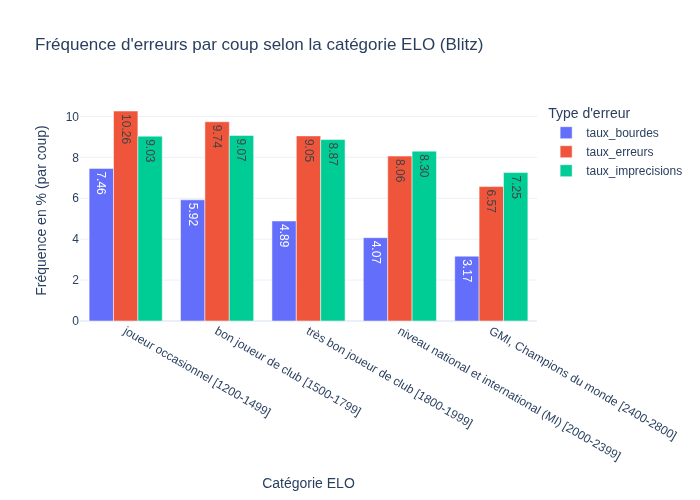

In [19]:
df_plot = resultat_q1.toPandas()
# enlève la catégorie autre
df_plot = df_plot[df_plot['Niveau'] != "Autre"].sort_values('Niveau')

cols_to_pct = ["taux_bourdes", "taux_erreurs", "taux_imprecisions"]
df_plot[cols_to_pct] = df_plot[cols_to_pct] * 100

df_melted = df_plot.melt(id_vars="Niveau",
                         value_vars=cols_to_pct,
                         var_name="Type d'erreur",
                         value_name="Pourcentage (%)")

fig = px.bar(df_melted,
             x="Niveau",
             y="Pourcentage (%)",
             color="Type d'erreur",
             barmode="group",
             title="Fréquence d'erreurs par coup selon la catégorie ELO (Blitz)",
             labels={"Pourcentage (%)": "Fréquence en % (par coup)", "Niveau": "Catégorie ELO"},
             template="plotly_white",
             text_auto='.2f')

fig.update_layout(xaxis={'categoryorder':'total descending'})

fig.write_image("plots/erreurs_par_niveau_elo.png")
display(Image(filename="plots/erreurs_par_niveau_elo.png"))

fig.show()

## Question 2
Probabilité de gagner avec une ouverture:
- **question A**   
&rarr; Avec quelle ouverture les blancs ont ils le plus de chance de gagner, par catégorie de niveau et par type de partie (Blitz et Classique).

- **question B**  
&rarr; même question avec les noirs.

### Introduction  

**Idée du calcul**  
L'objectif est d'identifier l'ouverture la plus performante pour les pions blancs (donc celle où le joueur a gagné la partie) en calculant la probabilité de victoire. On se concentre uniquement sur les jeu Blitz et Classical et par catégorie de niveau donc en fonction de l'ELO des joueurs.  

Pour que nos résultats soient fiables, nous ne gardons que les ouvertures qui ont été jouées au moins 50 fois. Cela évite qu'une ouverture chanceuse jouée seulement une ou deux fois ne se retrouve en première position. Ensuite, nous utilisons des Window Functions qui permettent de trier et de classer les ouvertures à l'intérieur de chaque groupe.

**Hypthèses**  
Pour les débutants, on pense que les ouvertures qui marchent le mieux sont celles qui attaquent tout de suite et sont très agressives au début. Des ouvertures comme le *coup du Berger* (qui fait mat en 4 coups) ou l'*attaque Fried Liver* car les adversaires ne savent pas encore bien défendre leurs pions. Donc nous pensons que ce sera plutôt des ouvertures qui jouent sur la suprise et l'agressivité.  

Pour les joueurs avec un ELO plus élevé, on s'attend à voir des ouvertures plus classiques comme la *partie espagnole* ou *queen's gambit* qui cherchent surtout à contrôler le centre et à construire un avantage sur la durée.  

Le fait de jouer avec les blancs donne sûrement un avantage au départ car ils jouent en premier et peuvent choisir le type de partie. Par exemple avec la *partie écossaise*, les blancs forcent rapidement un jeu ouvert et obligent les noirs à s'adapter.

**Variables utilisées**  
- **Result** : Le résultat final du match, utilisé pour identifier les victoires blanches (1-0) ou noires (0-1).
- **Game_type** : Type de cadence de la partie (on se limite à *Classical* et *Blitz* pour cette question)
- **Opening**: Nom de l'ouverture de la partie

### Code

#### Question A

In [20]:
# on filtre les jeux de types Blitz et Classical
df_q2 = df.filter(F.col("Game_type").isin("Blitz", "Classical"))

In [21]:
# on calcule l'elo moyen pour définir la catégorie de la partie comme avant
df_q2_EloGameMoyen = df_q2.withColumn("EloMoyen", (F.col("WhiteElo") + F.col("BlackElo")) / 2)

In [22]:
# on créé les catégories comme avant
df_blitz_classical_with_categoriesNiveau = df_q2_EloGameMoyen.withColumn("Niveau",
    F.when(F.col("EloMoyen").between(1200, 1499), "joueur occasionnel [1200-1499]")
     .when(F.col("EloMoyen").between(1500, 1799), "bon joueur de club [1500-1799]")
     .when(F.col("EloMoyen").between(1800, 1999), "très bon joueur de club [1800-1999]")
     .when(F.col("EloMoyen").between(2000, 2399), "niveau national et international (MI) [2000-2399]")
     .when(F.col("EloMoyen").between(2400, 2800), "GMI, Champions du monde [2400-2800]")
     .otherwise("Autre"))

In [23]:
# on a remarqué que pour la catégorie des joueurs avec l'ELO le plus élevé, les jeux classiques ne contiennent
# pas assez de parties, donc on baisse exceptionnement la limite de nb de parties pour cette catégorie
is_gmi_classical = (F.col("Niveau").contains("GMI")) & (F.col("Game_type") == "Classical")

# on filtre sur les openings qui ont été jouées plus de 50 fois pour être sûrs de la cohérence du résultat
openings_blancs_wins = df_blitz_classical_with_categoriesNiveau.groupBy("Niveau", "Game_type", "Opening").agg(
    F.count("*").alias("NbParties"),
    F.avg(F.when(F.col("Result") == "1-0", 1).otherwise(0)).alias("WinRate_White")
).filter(
    (is_gmi_classical & (F.col("NbParties") >= 5)) |
    (~is_gmi_classical & (F.col("NbParties") >= 50)))

In [24]:
# on récupère l'opening avec le WinRate max pour chaque niveau et game_type
window_blancs = Window.partitionBy("Niveau", "Game_type").orderBy(F.desc("WinRate_White"))

top_opening_blancs = openings_blancs_wins.withColumn("rang", F.row_number().over(window_blancs)) \
    .filter(F.col("rang") == 1).drop("rang")

top_opening_blancs.orderBy("Niveau", "Game_type").show(truncate=False)

+-------------------------------------------------+---------+-------------------------------------------------------------+---------+------------------+
|Niveau                                           |Game_type|Opening                                                      |NbParties|WinRate_White     |
+-------------------------------------------------+---------+-------------------------------------------------------------+---------+------------------+
|Autre                                            |Blitz    |Zukertort Opening: Vos Gambit                                |65       |0.7076923076923077|
|Autre                                            |Classical|King's Knight Opening                                        |55       |0.7090909090909091|
|GMI, Champions du monde [2400-2800]              |Blitz    |English Opening: Caro-Kann Defensive System                  |59       |0.6101694915254238|
|GMI, Champions du monde [2400-2800]              |Classical|Sicilian Defense: Del

#### Question B

In [25]:
# on filtre à nouveau pour min 50 parties jouées avec cet opening
openings_noirs_wins = df_blitz_classical_with_categoriesNiveau.groupBy("Niveau", "Game_type", "Opening").agg(
    F.count("*").alias("NbParties"),
    F.avg(F.when(F.col("Result") == "0-1", 1).otherwise(0)).alias("WinRate_Black")
).filter(
    (is_gmi_classical & (F.col("NbParties") >= 5)) |
    (~is_gmi_classical & (F.col("NbParties") >= 50)))

# on group by niveau et game_type
window_noirs = Window.partitionBy("Niveau", "Game_type").orderBy(F.desc("WinRate_Black"))

top_ouvertures_noirs = openings_noirs_wins.withColumn("rang", F.row_number().over(window_noirs)) \
    .filter(F.col("rang") == 1).drop("rang")

top_ouvertures_noirs.orderBy("Niveau", "Game_type").show(truncate=False)

+-------------------------------------------------+---------+------------------------------------------------+---------+------------------+
|Niveau                                           |Game_type|Opening                                         |NbParties|WinRate_Black     |
+-------------------------------------------------+---------+------------------------------------------------+---------+------------------+
|Autre                                            |Blitz    |Barnes Opening: Walkerling                      |67       |0.6716417910447762|
|Autre                                            |Classical|Sicilian Defense                                |67       |0.6268656716417911|
|GMI, Champions du monde [2400-2800]              |Blitz    |English Opening: King's English Variation       |62       |0.6129032258064516|
|GMI, Champions du monde [2400-2800]              |Classical|Sicilian Defense: Delayed Alapin Variation      |5        |0.6               |
|bon joueur de club 

### Conclusion

Pendant nos calculs, nous avons remarqué un manque de données pour la catégorie des joueurs champions du monde (GMI) en mode Classique. Avec notre seuil initial de 50 parties aucune ouverture ne ressortait car les joueurs de très haut niveau privilégient principalement le mode Blitz sur Lichess. Pour analyser cette catégorie sans fausser les autres résultats, nous avons abaissé le seuil à 5 parties minimum uniquement pour les GMI en Classique. Nous précisons toutefois que ces résultats spécifiques sont à interpréter avec prudence en raison de ce faible échantillon.  

De manière générale, on remarque que chez les débutants, les meilleures ouvertures permettent de gagner très souvent avec des taux atteignant 80 % de victoires. Chez les joueurs avec un ELO plus élevé, ces scores redescendent autour de 60 %. Cela confirme que les meilleurs joueurs savent mieux se défendre, rendant les parties beaucoup plus équilibrées.  

Notre première hypothèse, qui supposait que les débutants gagneraient davantage avec des ouvertures agressives est confirmée. C'est le cas de l'**Italian Game: Two Knights Defense, Knight Attack** en mode **Classique**, qui punit rapidement les erreurs de défense. À l'inverse, pour le haut niveau les attaques rapides disparaissent car les pièges sont connus. On observe des ouvertures plus stratégiques visant le contrôle du centre comme l'**English Opening**.

Notre idée initiale selon laquelle les blancs maîtrisent plus facilement la partie est à nuancer car les noirs obtiennent également d'excellents succès. Chez les débutants, l'ouverture **Kadas** en est la preuve. Environ 80 % des joueurs noirs gagnent lorsque les blancs choisissent ce premier coup. Cette stratégie est effectivement reconnue comme une erreur majeure. Le joueur Eric Schiller expliquait d'ailleurs que le coup "1. h4" crée des faiblesses immédiates sans compensation, ce que nos statistiques confirment réellement.

Enfin, nous remarquons une tendance liée au type du jeu. En mode **Blitz**, les probabilités de gain pour les meilleures ouvertures sont souvent plus élevées qu'en **Classique**. Le mode **Classique** laisse plus de temps pour réfléchir, ce qui favorise l'équilibre. En revanche, le **Blitz** réduit le temps de réaction ce qui permet à une ouverture surprenante d'être beaucoup plus efficace.

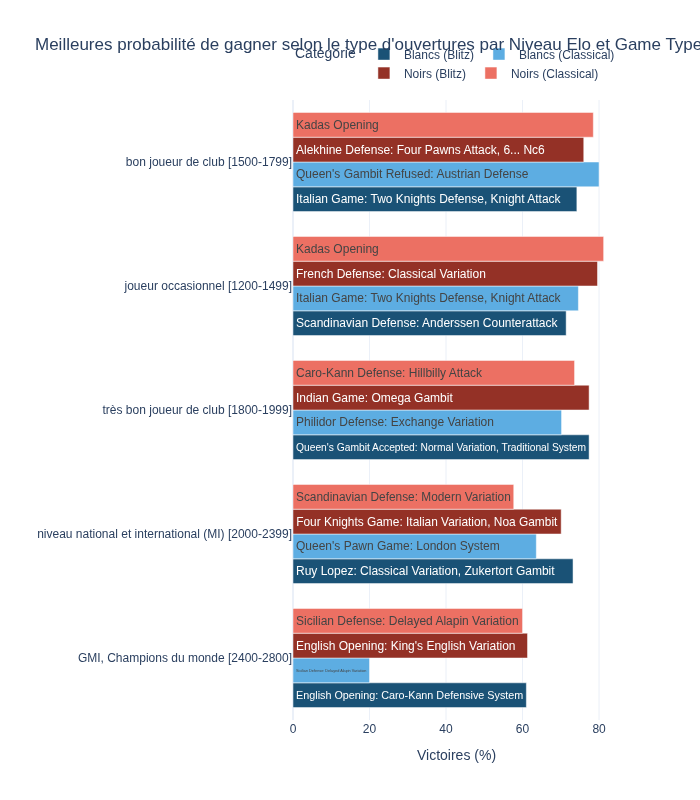

In [26]:
# conversion et fusion des données
df_b = top_opening_blancs.toPandas().rename(columns={'WinRate_White': 'WinRate'})
df_b['Joueur'] = 'Blancs'

df_n = top_ouvertures_noirs.toPandas().rename(columns={'WinRate_Black': 'WinRate'})
df_n['Joueur'] = 'Noirs'

df_total = pd.concat([df_b, df_n])
df_total = df_total[df_total['Niveau'] != "Autre"]
df_total['WinRate'] = (df_total['WinRate'] * 100).round(1)

df_total['Type'] = df_total['Joueur'] + " (" + df_total['Game_type'] + ")"

# couleurs du graphique en fonction des pions et game_type
color_map = {
    "Blancs (Blitz)": "#1A5276",
    "Blancs (Classical)": "#5DADE2",
    "Noirs (Blitz)": "#943126",
    "Noirs (Classical)": "#EC7063"
}

# graphique
fig = px.bar(df_total,
             y="Niveau",
             x="WinRate",
             color="Type",
             barmode="group",
             orientation='h',
             text="Opening",
             color_discrete_map=color_map,
             title="Meilleures probabilité de gagner selon le type d'ouvertures par Niveau Elo et Game Type (Blitz, Clasical)",
             labels={"WinRate": "Victoires (%)", "Type": "Catégorie", "Niveau": ""},
             template="plotly_white",
             height=800)

fig.update_traces(textposition='inside', insidetextanchor='start')
fig.update_layout(yaxis={'categoryorder':'total ascending'},
                  legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1))


fig.write_image("plots/meilleures_ouvertures.png")
display(Image(filename="plots/meilleures_ouvertures.png"))

fig.show()

## Question 3
Est ce qu'une ligne de données du fichier permet de prédire l'issue du match (colonne Result), et avec quelle probabilité. En d'autres termes, est ce que certaines des variables, comme le nombre d'erreurs (mistakes, blunders, inacurracies, ts_blunders), la différence d'ELO entre les deux joueurs, etc peuvent expliquer le résultat (victoire/défaite) ? Vous êtes libres de définir expliquer comme vous le souhaitez. Cela peut être une corrélation, linéaire ou non, ou tout autre relation permettant cette prédiction.

### Introduction  
**Idée du calcul**

L'objectif de cette section est de déterminer si les statistiques d'une partie de jeu d'échecs (erreurs, niveau des joueurs, gestion du temps) permettent de prédire le vainqueur.   

Nous utilisons une Pipeline Spark MLlib basée sur la régression logistique. Cela permet de calculer une probabilité de victoire en attribuant un poids (coefficient) à chaque variable après avoir normalisé les données avec un StandardScaler. Le modèle apprend sur 80 % des données pour ensuite prédire le résultat sur les 20 % restants.  

Nous avons globalement suivi ce que nous avons fait en tp avec MLib. Nous enchaînons un Transformer (VectorAssembler) pour regrouper les caractéristiques, un Estimator (StandardScaler) pour normaliser les écarts d'ELO et d'erreurs et ensuite un modèle de LogisticRegression.

**Hypothèses**  

Une première hypothèse serait que les variables les plus conséquents sur le résultat d'un match sont une haute différence d'ELO, un haut taux d'erreur de la part d'un des joueur notamment les fautes graves commisent sous le coup de la pression (*ts_blunders*).

**Variables utilisées**  
- **EloDiff** : Écart de niveau entre les deux joueurs
- **BlunderDiff** : Différence de fautes graves (bourdes) commises
- **MistakeDiff** : Différence d'erreurs moyennes commises
- **InaccuracyDiff** : Différence d'imprécisions commises
- **TimePressureDiff** : Écart de fautes commises sous moins de 10 secondes.


###Code

26/10/31 12:15:19 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/10/31 12:15:35 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


Aire sous la courbe (AUC) : 0.9135


Probabilité de prédiction correcte (accuracy) : 85.84%


+------+-----+----------+--------------------+
|Result|label|prediction|         probability|
+------+-----+----------+--------------------+
|   0-1|    0|       0.0|[0.91361108738200...|
|   1-0|    1|       1.0|[0.03837222404883...|
|   0-1|    0|       0.0|[0.69522210625763...|
|   1-0|    1|       1.0|[0.21731422053406...|
|   0-1|    0|       0.0|[0.86570092888252...|
|   1-0|    1|       1.0|[0.11947249203894...|
|   1-0|    1|       1.0|[0.10466849750149...|
|   1-0|    1|       1.0|[0.46480355803299...|
|   1-0|    1|       1.0|[0.25082565073505...|
|   1-0|    1|       1.0|[0.05321793511109...|
+------+-----+----------+--------------------+
only showing top 10 rows



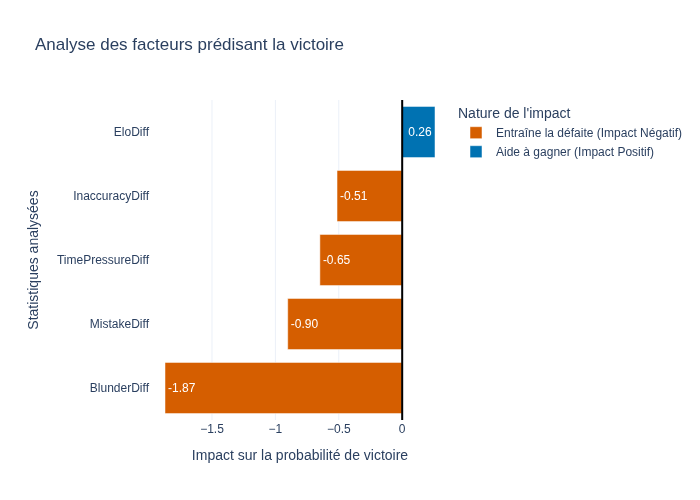

In [27]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

# échantillonage du dataset (on prend 10% des données)
df_sample = df.sample(withReplacement=False, fraction=0.1, seed=42)

# préparation des variables
  # label: 1 si les blancs gagnent sinon 0
  # EloDiff: qui est le joueur le plus fort (si positif c'est les blancs)
  # BlunderDiff: qui a fait le plus d'erreurs (si positif c'est les blancs)
  # MistakeDiff: même idée que BlunderDiff mais pour les erreurs
  # InaccuracyDiff: même idée que pour BlunderDiff
  # TimePressureDiff: qui a fait le plus de bourdes sous une pression du temps (si positif c'est les blancs)
df_ml = df_sample.withColumn("label", F.when(F.col("Result") == "1-0", 1).otherwise(0)) \
          .withColumn("EloDiff", F.col("WhiteElo") - F.col("BlackElo")) \
          .withColumn("BlunderDiff", F.col("White_blunders") - F.col("Black_blunders")) \
          .withColumn("MistakeDiff", F.col("White_mistakes") - F.col("Black_mistakes")) \
          .withColumn("InaccuracyDiff", F.col("White_inaccuracies") - F.col("Black_inaccuracies")) \
          .withColumn("TimePressureDiff", F.col("White_ts_blunders") - F.col("Black_ts_blunders"))

# features que l'on pense ont un impact sur le gagnant du jeu
features_list = ["EloDiff", "BlunderDiff", "MistakeDiff", "InaccuracyDiff", "TimePressureDiff"]
# on regroupe tout dans un vecteur
assembler = VectorAssembler(inputCols=features_list, outputCol="vec_features")
# normalisation des données
scaler = StandardScaler(inputCol="vec_features", outputCol="features")

lr = LogisticRegression(featuresCol="features", labelCol="label")

# automatisation des étapes
pipeline = Pipeline(stages=[assembler, scaler, lr])

# entraînement
train_data, test_data = df_ml.randomSplit([0.8, 0.2], seed=42)
model = pipeline.fit(train_data)
predictions = model.transform(test_data)

# vérification de la performance de notre modèle avec aire under the curve
evaluator = BinaryClassificationEvaluator(labelCol="label")
auc = evaluator.evaluate(predictions)
print(f"Aire sous la courbe (AUC) : {auc:.4f}")

# calcul de l'accuracy
evaluator_acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
accuracy = evaluator_acc.evaluate(predictions)

print(f"Probabilité de prédiction correcte (accuracy) : {accuracy*100:.2f}%")

predictions.select("Result", "label", "prediction", "probability").show(10)

# graphique
# extrait les coeff du modèle
lr_model = model.stages[-1]
coeff_df = pd.DataFrame({
    'Variable': features_list,
    'Coefficient': lr_model.coefficients.toArray()
})

# légendes des catégories
coeff_df['Influence'] = coeff_df['Coefficient'].apply(
    lambda x: "Aide à gagner (Impact Positif)" if x > 0 else "Entraîne la défaite (Impact Négatif)"
)

# tri des variables
coeff_df = coeff_df.sort_values(by='Coefficient', ascending=True)

fig = px.bar(
    coeff_df,
    x='Coefficient',
    y='Variable',
    orientation='h',
    title="Analyse des facteurs prédisant la victoire",
    color='Influence',
    color_discrete_map={
        "Aide à gagner (Impact Positif)": "#0072B2",
        "Entraîne la défaite (Impact Négatif)": "#D55E00"
    },
    labels={'Coefficient': 'Force de l\'impact', 'Variable': 'Variables du match'},
    template="plotly_white",
    text_auto='.2f'
)

fig.add_vline(x=0, line_dash="solid", line_color="black")

fig.update_layout(
    xaxis_title="Impact sur la probabilité de victoire",
    yaxis_title="Statistiques analysées",
    legend_title="Nature de l'impact",
    showlegend=True,
    margin=dict(l=150)
)

fig.write_image("plots/facteurs_prediction_victoire.png")
display(Image(filename="plots/facteurs_prediction_victoire.png"))

fig.show()

### Conclusion

Grâce à notre modèle, une ligne de données permet de prédire l'issue du match avec une accuracy de 85,84%% et avec une AUC (Aire sous la courbe) de 0.9135.

On remarque qu'il y a une hiérarchie dans les facteurs de victoire :  

- **Les erreurs sont conséquentes** : la variable *BlunderDiff* possède le coefficient négatif le plus élevé ce qui confirme que commettre une bourde de plus que l'adversaire est le meilleur prédicteur d'une défaite.

- **L'ELO n'est pas suffisant pour la prédiction** : bien que l'EloDiff ait un impact positif, sa force est bien moindre que celle des erreurs commises durant la partie.  

- **La pression a un fort impact** : La variable TimePressureDiff confirme que la gestion du stress en fin de coup est un indicateur fiable pour prédire la défaite d'un joueur.    

## Question 4 choisie: Influence de l'ouverture sur les renversements de situation

### Introduction
**Idée de calcul**  
L'objectif est de mesurer la "stabilité" d'une partie selon l'ouverture choisie. Pour garantir la pertinence, comme plus haut nous isolons d'abord les 50 ouvertures les plus fréquentes du dataset. Cela évite que des ouvertures rares, jouées seulement quelques fois n'affichent des moyennes extrêmes qui fausseraient l'analyse.  
Nous calculons ensuite la moyenne, le minimum et le maximum de la variable *Game_flips* pour chaque ouverture, en segmentant par type de partie (Game_type) pour observer si la cadence donc le temps de réflexion du joueur accentue ces retournements.  

**Hypothèse**  
Nous supposons que les ouvertures agressives dites ouvertes provoquent un nombre de renversements de situation plus élevé. À l'inverse, des ouvertures classiques devraient mener à des parties plus stables où l'avantage change moins souvent de camp. Nous pensons également que le type de jeu (Blitz, Classical,..) peut avoir un impact car le manque de temps en Blitz peut générer plus de retournements.

**Variables utilisées**  
- **Opening** : le nom de l'ouverture
- **Game_flips** : le nombre de fois où l'avantage a basculé entre les blancs et les noirs durant la partie
- **Game_type** : Le type de partie

### Code

In [28]:
top_op = [row['Opening'] for row in df.groupBy("Opening").count().orderBy("count", ascending=False)
            .limit(50).collect()]

df_top = df.filter(df["Opening"].isin(top_op))

df_top.select("Opening").distinct().show(20)

+--------------------+
|             Opening|
+--------------------+
|   Queen's Pawn Game|
|Queen's Pawn Game...|
|Queen's Pawn Game...|
|    Sicilian Defense|
|    Philidor Defense|
|Italian Game: Ant...|
|Queen's Gambit De...|
|         Indian Game|
|Scandinavian Defe...|
|   Hungarian Opening|
|Queen's Gambit Re...|
|    Bishop's Opening|
|Four Knights Game...|
|Sicilian Defense:...|
|Sicilian Defense:...|
|        Queen's Pawn|
|Queen's Pawn Game...|
|Ruy Lopez: Steini...|
|      Modern Defense|
|         Scotch Game|
+--------------------+
only showing top 20 rows



In [29]:
df_stats = (
    df_top.filter(F.col("Game_type") != "Correspondence")
    .groupBy("Opening", "Game_type")
    .agg(
      F.min("Game_flips").alias("min_flips"),
      F.max("Game_flips").alias("max_flips"),
      F.avg("Game_flips").alias("avg_flips"),
      F.count("*").alias("n_games")
     )
    .orderBy("Opening", "Game_type")
    )

df_stats.orderBy(F.desc("avg_flips")).show(10, truncate=False)
df_stats.orderBy(F.asc("avg_flips")).show(10, truncate=False)

+-------------------------------------+---------+---------+---------+------------------+-------+
|Opening                              |Game_type|min_flips|max_flips|avg_flips         |n_games|
+-------------------------------------+---------+---------+---------+------------------+-------+
|Van't Kruijs Opening                 |Blitz    |0        |47       |6.953505467242488 |21766  |
|French Defense: Normal Variation     |Blitz    |0        |41       |6.932019574130406 |7561   |
|King's Pawn Game: Leonardis Variation|Blitz    |0        |44       |6.920922256097561 |10496  |
|Queen's Pawn                         |Blitz    |0        |59       |6.901180902702311 |13803  |
|French Defense: Normal Variation     |Rapid    |0        |37       |6.899134790528233 |4392   |
|Hungarian Opening                    |Blitz    |0        |48       |6.890093866763875 |10973  |
|Old Benoni Defense                   |Rapid    |0        |32       |6.882747729964469 |2533   |
|Owen Defense                 

+------------------------------------+---------+---------+---------+------------------+-------+
|Opening                             |Game_type|min_flips|max_flips|avg_flips         |n_games|
+------------------------------------+---------+---------+---------+------------------+-------+
|French Defense: Exchange Variation  |Classical|0        |22       |4.74792899408284  |845    |
|Queen's Pawn Game: London System    |Classical|0        |24       |4.868804664723032 |686    |
|Giuoco Piano                        |Classical|0        |28       |5.224824355971897 |854    |
|Scandinavian Defense: Main Line     |Classical|0        |20       |5.266666666666667 |495    |
|French Defense: Exchange Variation  |Rapid    |0        |38       |5.281072298943948 |4924   |
|Ruy Lopez: Steinitz Defense         |Classical|0        |28       |5.28953488372093  |860    |
|Queen's Gambit Declined             |Classical|0        |29       |5.313997477931904 |793    |
|Indian Game                         |Cl

### Conclusion
Contrairment à notre hypothèse initiale, l'opening n'influence pas le nombre de renversement de situation, puique le nombre moyen a une très faible variance (entre 4 et 7).  

Toutefois, on peut observer un autre phénomène, qui est la corrélation entre le type de partie et le nombre de renversements.  
En effet, il existe un plus haut nombre de renversements dans les parties Blitz que la version classique. Cela peut s'expliquer par la pression du temps qui est beaucoup plus forte en Blitz.

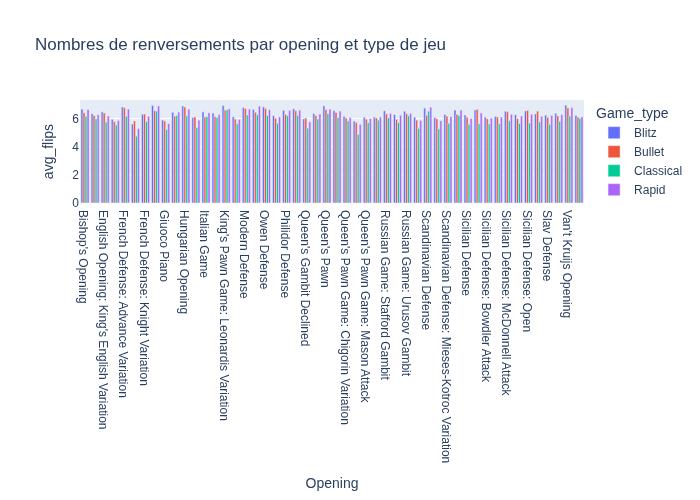

In [30]:
#graphique
fig = px.bar(df_stats, x="Opening", y="avg_flips", title="Nombres de renversements par opening et type de jeu", color="Game_type", barmode="group")

fig.write_image("plots/nb_renversements_par_opening_type_jeu.png")
display(Image(filename="plots/nb_renversements_par_opening_type_jeu.png"))

fig.show()


In [31]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
